In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils import resample

In [2]:
# --- Load data ---
db_path = 'sqlite:///Maji_Ndogo_farm_survey_small.db'
engine = create_engine(db_path)

sql_query = """
SELECT *
FROM geographic_features
LEFT JOIN weather_features USING (Field_ID)
LEFT JOIN soil_and_crop_features USING (Field_ID)
LEFT JOIN farm_management_features USING (Field_ID)
"""

with engine.connect() as connection:
    MD_df = pd.read_sql_query(text(sql_query), connection)

# --- Standard cleaning pipeline from earlier in the programme ---
MD_df.rename(columns={'Annual_yield': 'Crop_type_Temp', 'Crop_type': 'Annual_yield'}, inplace=True)
MD_df.rename(columns={'Crop_type_Temp': 'Crop_type'}, inplace=True)
MD_df['Elevation'] = MD_df['Elevation'].abs()

def correct_crop_type(crop):
    corrections = {'cassaval': 'cassava', 'wheatn': 'wheat', 'teaa': 'tea'}
    return corrections.get(str(crop).strip(), str(crop).strip())

MD_df['Crop_type'] = MD_df['Crop_type'].apply(correct_crop_type)

print(f"DataFrame shape: {MD_df.shape}")
print(f"\nCrop type distribution:")
print(MD_df['Crop_type'].value_counts())

DataFrame shape: (5654, 18)

Crop type distribution:
Crop_type
wheat      1342
tea         913
potato      823
cassava     672
banana      633
coffee      607
maize       399
rice        265
Name: count, dtype: int64


In [3]:
df = MD_df 
display(df.head())

,Field_ID,Elevation,Latitude,Longitude,Location,Slope,Rainfall,Min_temperature_C,Max_temperature_C,Ave_temps,Soil_fertility,Soil_type,pH,Pollution_level,Plot_size,Annual_yield,Crop_type,Standard_yield
0,40734,786.05580,-7.389911,-7.556202,Rural_Akatsi,14.795113,1125.2,-3.1,33.1,15.00,0.62,Sandy,6.169393,0.085267,1.3,0.751354,cassava,0.577964
1,30629,674.33410,-7.736849,-1.051539,Rural_Sokoto,11.374611,1450.7,-3.9,30.6,13.35,0.64,Volcanic,5.676648,0.399684,2.2,1.069865,cassava,0.486302
2,39924,826.53390,-9.926616,0.115156,Rural_Sokoto,11.339692,2208.9,-1.8,28.4,13.30,0.69,Volcanic,5.331993,0.358029,3.4,2.208801,tea,0.649647
3,5754,574.94617,-2.420131,-6.592215,Rural_Kilimani,7.109855,328.8,-5.8,32.2,13.20,0.54,Loamy,5.328150,0.286687,2.4,1.277635,cassava,0.532348
4,14146,886.35300,-3.055434,-7.952609,Rural_Kilimani,55.007656,785.2,-2.5,31.0,14.25,0.72,Sandy,5.721234,0.043190,1.5,0.832614,wheat,0.555076


In [4]:
# Check the dtatypes of the columns
for col in df.columns:
    print(f"{col:<20}: {df[col].dtype}")

Field_ID            : int64
Elevation           : float64
Latitude            : float64
Longitude           : float64
Location            : str
Slope               : float64
Rainfall            : float64
Min_temperature_C   : float64
Max_temperature_C   : float64
Ave_temps           : float64
Soil_fertility      : float64
Soil_type           : str
pH                  : float64
Pollution_level     : float64
Plot_size           : float64
Annual_yield        : float64
Crop_type           : str
Standard_yield      : float64


## **[Analysis]()**

### **Challenge 1: Feature Selection and Encoding**

Before modeling, we choose our features and prepare the target. We use the environmental and geographic features Sanaa has curated over earlier courses, and encode the crop target as numeric labels.

### **Task**
Create a function `prepare_crop_features` that:
- Takes the full Maji Ndogo DataFrame.
- Selects these feature columns: `Elevation`, `Rainfall`, `Min_temperature_C`, `Max_temperature_C`, `Ave_temps`, `Soil_fertility`, `pH`, `Pollution_level`, `Slope`, `Plot_size`.
- Drops rows with any missing values in the selected columns or the target `Crop_type`.
- Encodes `Crop_type` using a `LabelEncoder` into a new column `Crop_encoded`.
- Returns `(df_prepared, feature_cols, le)`, where `df_prepared` contains the feature columns **and** `Crop_encoded`, `feature_cols` is the feature-name list, and `le` is the fitted `LabelEncoder`.
    

In [5]:
def prepare_crop_features(df):
    feature_cols = [
        "Elevation",
        "Rainfall",
        "Min_temperature_C",
        "Max_temperature_C",
        "Ave_temps",
        "Soil_fertility",
        "pH",
        "Pollution_level",
        "Slope",
        "Plot_size"
    ]

    # Select features and target, then remove missing values
    df_prepared = df[feature_cols + ["Crop_type"]].dropna().copy()

    # Encode Crop_type
    le = LabelEncoder()
    df_prepared["Crop_encoded"] = le.fit_transform(
        df_prepared["Crop_type"]
    )

    # Keep only features and encoded target
    df_prepared = df_prepared[
        feature_cols + ["Crop_encoded"]
    ]

    return df_prepared, feature_cols, le

In [6]:
df_prepared, feature_cols, le = prepare_crop_features(df)

print("Prepared DataFrame shape:", df_prepared.shape)
print("Feature columns:", feature_cols)
print("Crop classes:", le.classes_)

print("\nEncoded target distribution:")
print(
    df_prepared["Crop_encoded"]
    .map(dict(enumerate(le.classes_)))
    .value_counts()
)

Prepared DataFrame shape: (5654, 11)
Feature columns: ['Elevation', 'Rainfall', 'Min_temperature_C', 'Max_temperature_C', 'Ave_temps', 'Soil_fertility', 'pH', 'Pollution_level', 'Slope', 'Plot_size']
Crop classes: ['banana' 'cassava' 'coffee' 'maize' 'potato' 'rice' 'tea' 'wheat']

Encoded target distribution:
Crop_encoded
wheat      1342
tea         913
potato      823
cassava     672
banana      633
coffee      607
maize       399
rice        265
Name: count, dtype: int64


 ### **Challenge 2: Training a Multiclass Logistic Regression Classifier**

Logistic Regression handles multiclass problems by fitting one classifier per class (one-vs-rest) or by extending to a softmax across all classes at once; `sklearn` manages this automatically.

### Task
Create a function `train_crop_classifier` that:
- Takes `df_prepared`, `feature_cols`, `random_state` (default `42`), and `model_type` (`'logistic'` or `'random_forest'`).
- Splits the data 80–20 (features = `feature_cols`, target = `Crop_encoded`), using `random_state`.
- Trains the selected model: `LogisticRegression(max_iter=1000)` or `RandomForestClassifier(n_estimators=100, random_state=random_state)`.
- Returns `(model, X_test, y_test)`.

In [12]:
def train_crop_classifier(
    df_prepared,
    feature_cols,
    random_state=42,
    model_type="logistic"
):
    # Define features and target
    X = df_prepared[feature_cols]
    y = df_prepared["Crop_encoded"]

    # Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=random_state,
        stratify=y
    )

    # Select model
    if model_type == "logistic":

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(max_iter=1000))
        ])

    elif model_type == "random_forest":
        model = RandomForestClassifier(
            n_estimators=100,
            random_state=random_state
        )

    else:
        raise ValueError(
            "model_type must be 'logistic' or 'random_forest'"
        )

    # Train model
    model.fit(X_train, y_train)

    return model, X_test, y_test

### **[Test the Logistic Model]()**

In [13]:
logistic_model, X_test, y_test = train_crop_classifier(
    df_prepared,
    feature_cols,
    model_type="logistic"
)

print("Logistic Regression trained successfully.")
print("Test set shape:", X_test.shape)
print("Number of classes:", len(logistic_model.classes_))

Logistic Regression trained successfully.
Test set shape: (1131, 10)
Number of classes: 8


### **[Test The Random Foreet Model]()**

In [10]:
rf_model, X_test, y_test = train_crop_classifier(
    df_prepared,
    feature_cols,
    model_type="random_forest"
)

print("Random Forest trained successfully.")
print("Test set shape:", X_test.shape)
print("Number of classes:", len(rf_model.classes_))

Random Forest trained successfully.
Test set shape: (1131, 10)
Number of classes: 8


In [14]:
logistic_model, X_test, y_test = train_crop_classifier(
    df_prepared,
    feature_cols,
    random_state=42,
    model_type="logistic"
)

y_pred = logistic_model.predict(X_test)

print(
    f"Logistic Regression accuracy: "
    f"{accuracy_score(y_test, y_pred):.4f}"
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=le.classes_
    )
)

Logistic Regression accuracy: 0.4527
              precision    recall  f1-score   support

      banana       0.34      0.35      0.34       127
     cassava       0.46      0.35      0.40       134
      coffee       0.46      0.41      0.44       121
       maize       0.26      0.06      0.10        80
      potato       0.47      0.52      0.49       165
        rice       0.23      0.15      0.18        53
         tea       0.68      0.77      0.72       183
       wheat       0.38      0.49      0.43       268

    accuracy                           0.45      1131
   macro avg       0.41      0.39      0.39      1131
weighted avg       0.44      0.45      0.44      1131



### **Challenge 3: The Confusion Matrix — Understanding Crop Misclassification**

A confusion matrix shows exactly which classes the model confuses with each other — in a multiclass problem, that is far more informative than accuracy alone. It tells Sanaa not just *how often* the model errs, but *what it mistakes for what*.

### __Task__
Create a function `plot_confusion_matrix` that:
- Takes a fitted `model`, `X_test`, `y_test`, and a list of `class_names`.
- Generates predictions.
- Plots the confusion matrix using `ConfusionMatrixDisplay` with `cmap='Blues'` (create a `plt.figure(figsize=(12, 10))` first).
- Returns the confusion matrix as a NumPy array (from `confusion_matrix`)

In [19]:
def plot_confusion_matrix(
    model,
    X_test,
    y_test,
    class_names
):
    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred
    )

    # Create figure
    plt.figure(figsize=(12, 10))

    # Plot confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        cmap="Blues",
        values_format="d",
        ax=plt.gca()
    )

    plt.tight_layout()
    plt.show()

    return cm

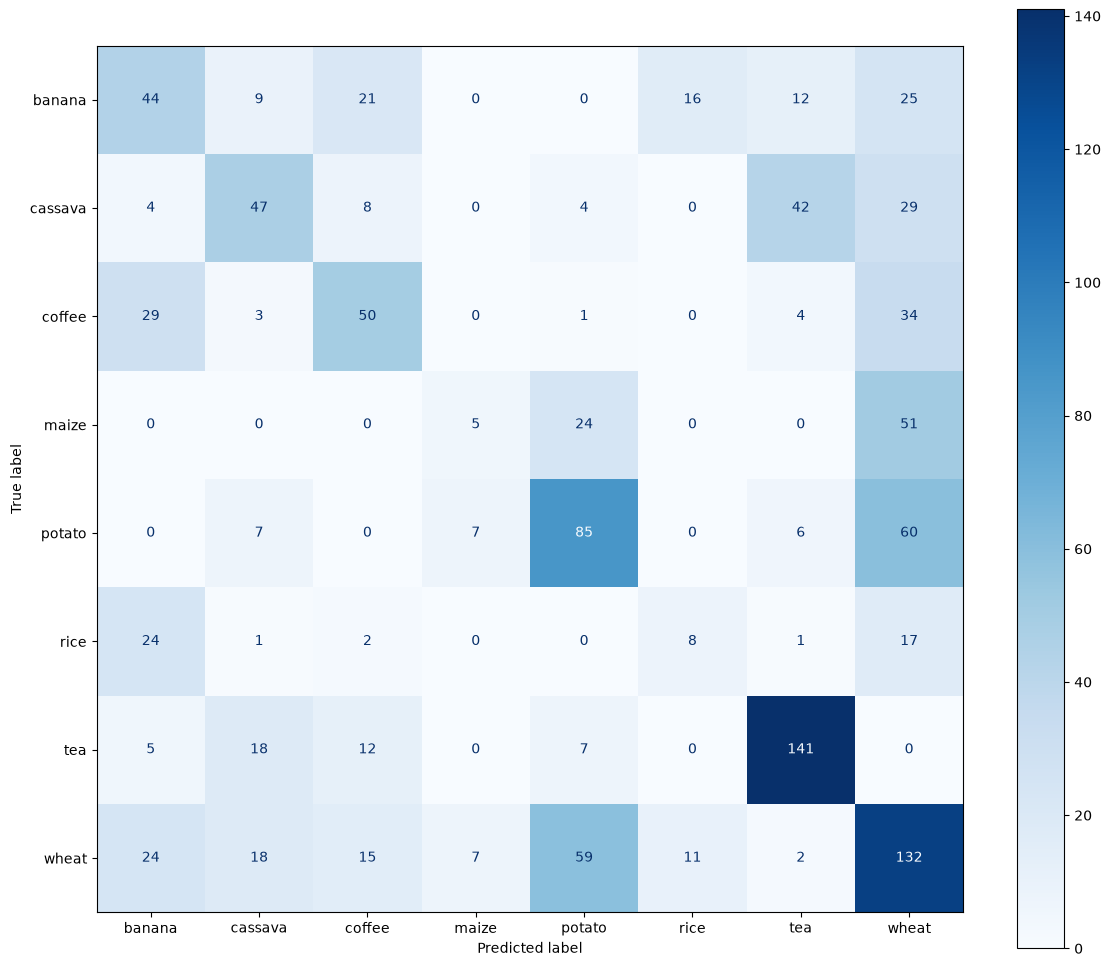

Confusion matrix shape: (8, 8)


In [20]:
cm = plot_confusion_matrix(
    logistic_model,
    X_test,
    y_test,
    le.classes_
)

print("Confusion matrix shape:", cm.shape)

### __Challenge 4: Addressing Class Imbalance — Upsampling__

When the target is imbalanced, a model tends to over-predict the majority class — inflating accuracy while quietly failing on minority crops. One fix is **upsampling**: resample the minority classes with replacement until every class matches the majority-class count.

### __Task__
Create a function `upsample_minority_classes` that:
- Takes `df_prepared` and `feature_cols`.
- Identifies the majority class (the most frequent `Crop_encoded` value) and its count `n`.
- Upsamples every other class to `n` rows using `sklearn.utils.resample` with `replace=True` and `random_state=42`.
- Concatenates all classes into one balanced DataFrame and returns it.
- Prints the class counts before and after balancing.

In [21]:
def upsample_minority_classes(df_prepared, feature_cols):
    # Display original class distribution
    print("Before balancing:")
    print(df_prepared["Crop_encoded"].value_counts().sort_index())

    # Identify majority class size
    n = df_prepared["Crop_encoded"].value_counts().max()

    # Store each class after resampling
    balanced_classes = []

    for class_label in df_prepared["Crop_encoded"].unique():

        class_data = df_prepared[
            df_prepared["Crop_encoded"] == class_label
        ]

        # Upsample minority classes
        if len(class_data) < n:
            class_data = resample(
                class_data,
                replace=True,
                n_samples=n,
                random_state=42
            )

        balanced_classes.append(class_data)

    # Combine all classes
    balanced_df = pd.concat(
        balanced_classes,
        ignore_index=True
    )

    # Keep features and target
    balanced_df = balanced_df[
        feature_cols + ["Crop_encoded"]
    ]

    print("\nAfter balancing:")
    print(
        balanced_df["Crop_encoded"]
        .value_counts()
        .sort_index()
    )

    print(
        "\nBalanced DataFrame shape:",
        balanced_df.shape
    )

    return balanced_df



In [22]:
balanced_df = upsample_minority_classes(
    df_prepared,
    feature_cols
)

Before balancing:
Crop_encoded
0     633
1     672
2     607
3     399
4     823
5     265
6     913
7    1342
Name: count, dtype: int64

After balancing:
Crop_encoded
0    1342
1    1342
2    1342
3    1342
4    1342
5    1342
6    1342
7    1342
Name: count, dtype: int64

Balanced DataFrame shape: (10736, 11)


In [23]:
print("\nClass distribution after balancing:")

print(
    balanced_df["Crop_encoded"]
    .map(dict(enumerate(le.classes_)))
    .value_counts()
)


Class distribution after balancing:
Crop_encoded
cassava    1342
tea        1342
wheat      1342
potato     1342
banana     1342
coffee     1342
rice       1342
maize      1342
Name: count, dtype: int64


In [25]:
X_balanced = balanced_df[feature_cols]
y_balanced = balanced_df["Crop_encoded"]

X_train_balanced, X_test_balanced, y_train_balanced, y_test_balanced = train_test_split(
    X_balanced,
    y_balanced,
    test_size=0.20,
    random_state=42,
    stratify=y_balanced
)

balanced_model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(max_iter=1000))
        ])

balanced_model.fit(
    X_train_balanced,
    y_train_balanced
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](8,)","[0,1,2,...,5,6,7]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Elevation','Rainfall','Min_temperature_C',...,'Pollution_level','Slope', 'Plot_size']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [26]:
y_pred_balanced = balanced_model.predict(X_test_balanced)

print(
    f"Balanced model accuracy: "
    f"{accuracy_score(y_test_balanced, y_pred_balanced):.4f}"
)

print(
    classification_report(
        y_test_balanced,
        y_pred_balanced,
        target_names=le.classes_
    )
)

Balanced model accuracy: 0.4870
              precision    recall  f1-score   support

      banana       0.28      0.20      0.23       268
     cassava       0.52      0.51      0.52       268
      coffee       0.48      0.53      0.50       269
       maize       0.49      0.55      0.52       269
      potato       0.46      0.53      0.49       269
        rice       0.63      0.68      0.65       268
         tea       0.65      0.73      0.69       269
       wheat       0.24      0.17      0.20       268

    accuracy                           0.49      2148
   macro avg       0.47      0.49      0.47      2148
weighted avg       0.47      0.49      0.47      2148



### __Challenge 5: Selecting the Best Model — Logistic Regression vs. Random Forest__

Having tried a linear model, let's see whether a Random Forest does better on this eight-class problem. Its ensemble of trees can capture the non-linear interactions between rainfall, soil, and crop suitability that a single linear boundary cannot.

### __Task__
Create a function `compare_classifiers` that:
- Takes `df_balanced`, `feature_cols`, and the `LabelEncoder` `le`.
- Trains both a `LogisticRegression(max_iter=1000)` and a `RandomForestClassifier(n_estimators=100, random_state=42)` on an 80–20 split (`random_state=42`).
- Prints the classification report for each.
- Returns a DataFrame with columns `model`, `accuracy`, `macro_f1` — one row per model.

> Use `classification_report(..., output_dict=True)['macro avg']['f1-score']` to extract macro F1 programmatically.

In [32]:
def compare_classifiers(df_balanced, feature_cols, le):

    # Define features and target
    X = df_balanced[feature_cols]
    y = df_balanced["Crop_encoded"]

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    # Define models
    models = {
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(max_iter=1000))
        ]),
        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    }

    results = []

    # Train and evaluate each model
    for name, model in models.items():

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        report = classification_report(
            y_test,
            y_pred,
            target_names=le.classes_,
            output_dict=True
        )

        accuracy = accuracy_score(
            y_test,
            y_pred
        )

        macro_f1 = report["macro avg"]["f1-score"]

        print(f"\n{name}")
        print("=" * len(name))
        print(
            classification_report(
                y_test,
                y_pred,
                target_names=le.classes_
            )
        )

        results.append({
            "model": name,
            "accuracy": accuracy,
            "macro_f1": macro_f1
        })

    return pd.DataFrame(results)

In [33]:
results = compare_classifiers(
    balanced_df,
    feature_cols,
    le
)

results


Logistic Regression
              precision    recall  f1-score   support

      banana       0.28      0.20      0.23       268
     cassava       0.52      0.51      0.52       268
      coffee       0.48      0.53      0.50       269
       maize       0.49      0.55      0.52       269
      potato       0.46      0.53      0.49       269
        rice       0.63      0.68      0.65       268
         tea       0.65      0.73      0.69       269
       wheat       0.24      0.17      0.20       268

    accuracy                           0.49      2148
   macro avg       0.47      0.49      0.47      2148
weighted avg       0.47      0.49      0.47      2148


Random Forest
              precision    recall  f1-score   support

      banana       0.88      0.85      0.87       268
     cassava       0.82      0.88      0.85       268
      coffee       0.82      0.94      0.87       269
       maize       0.83      0.97      0.89       269
      potato       0.78      0.89      0.8

,model,accuracy,macro_f1
0,Logistic Regression,0.486965,0.474826
1,Random Forest,0.838454,0.820371


### **Challenge 6: Telling Sanaa the Story — Precision, Recall, and Crop Confidence**

The final step turns metrics into something Sanaa can act on: which crops does the best model recommend with the highest confidence, and which deserve caution?

### **Task**
Create a function `crop_confidence_report` that:
- Takes the best fitted `model` (the Random Forest), `X_test`, `y_test`, and the `LabelEncoder` `le`.
- Generates predictions and extracts the classification report as a dictionary.
- Builds a DataFrame with columns `crop`, `precision`, `recall`, `f1_score`, `support` (filter out the `accuracy`, `macro avg`, and `weighted avg` summary rows).
- Sorts by `f1_score` descending.
- Plots a horizontal bar chart of F1 score by crop, with labeled axes and a title.
- Returns the sorted DataFrame.

In [38]:
def crop_confidence_report(model, X_test, y_test, le):
    # Generate predictions
    y_pred = model.predict(X_test)

    # Generate classification report as a dictionary
    report = classification_report(
        y_test,
        y_pred,
        target_names=le.classes_,
        output_dict=True
    )

    # Keep only individual crop classes
    crop_rows = {
        crop: metrics
        for crop, metrics in report.items()
        if crop in le.classes_
    }

    # Build DataFrame
    report_df = pd.DataFrame(crop_rows).T.reset_index()

    # Rename columns
    report_df = report_df.rename(
        columns={
            "index": "crop",
            "f1-score": "f1_score"
        }
    )

    # Keep required columns
    report_df = report_df[
        [
            "crop",
            "precision",
            "recall",
            "f1_score",
            "support"
        ]
    ]

    # Sort by F1-score
    report_df = report_df.sort_values(
        "f1_score",
        ascending=False
    ).reset_index(drop=True)

    # Plot F1-score
    fig, ax = plt.subplots(figsize=(9, 5))

    report_df.sort_values("f1_score").plot(
        kind="barh",
        x="crop",
        y="f1_score",
        ax=ax,
        legend=False
    )

    ax.set(
        title="F1 Score by Crop",
        xlabel="F1 Score",
        ylabel="Crop"
    )

    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis='both', which='both', left=False, right=False)

    ax.grid(axis='x', linestyle='--', alpha=0.3, zorder=0, color='gray')

    plt.tight_layout()
    plt.show()

    return report_df

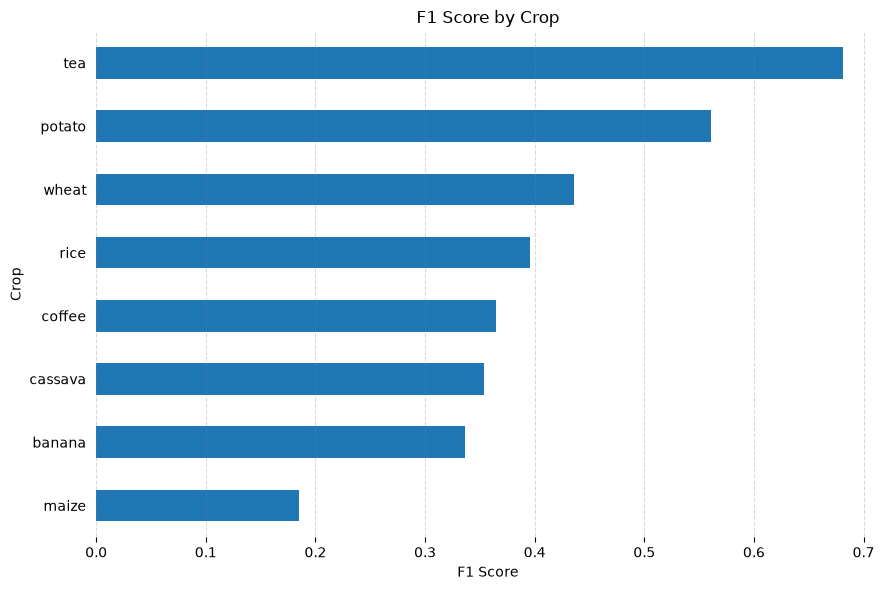

,crop,precision,recall,f1_score,support
0,tea,0.668421,0.693989,0.680965,183.0
1,potato,0.504854,0.630303,0.560647,165.0
2,wheat,0.415541,0.458955,0.436170,268.0
3,rice,0.416667,0.377358,0.396040,53.0
4,coffee,0.366667,0.363636,0.365145,121.0
5,cassava,0.365079,0.343284,0.353846,134.0
6,banana,0.350427,0.322835,0.336066,127.0
7,maize,0.357143,0.125000,0.185185,80.0


In [37]:
crop_report = crop_confidence_report(
    rf_model,
    X_test,
    y_test,
    le
)

crop_report